# Predictive Maintenance & Equipment Failure Analysis — AI4I 2020 (Improved Model)

This notebook builds an end-to-end predictive-maintenance classifier with a stronger modeling and evaluation workflow:

- Load and explore the AI4I 2020 dataset
- Engineer machine-condition features
- Prevent target leakage from failure-mode labels
- Use separate train / validation / test splits
- Establish Logistic Regression and Random Forest baselines
- Tune a Random Forest using **PR-AUC (Average Precision)**, which is more informative for rare failures
- Compare Logistic Regression, tuned Random Forest, and HistGradientBoosting
- Tune the decision threshold for maintenance-oriented recall
- Compare default vs tuned-threshold performance on an untouched test set
- Inspect feature importance and machine-level risk scores
- Optionally explain predictions with SHAP
- Interpret the recorded results, limitations, and maintenance implications

> Run the notebook from top to bottom. The tuning section may take a little longer than the baseline cells.

In [ ]:
# Uncomment this line if your environment is missing dependencies.
# %pip install -q pandas numpy matplotlib scikit-learn shap

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## 1. Load the AI4I 2020 dataset

**What we do**
- Load the AI4I 2020 predictive-maintenance dataset and inspect its size, schema, data types, and missing values.
- Verify that the expected sensor, operating-condition, target, and failure-mode variables are available.

**Why we do it**
- Data validation is the first step in a reliable ML workflow; modeling decisions depend on knowing exactly what information is present.
- The dataset contains **10,000 observations and 14 original variables**, with no missing values in this run, so no substantial missing-data treatment is required.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/601/data.csv"
LOCAL_FILE = "ai4i2020.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded dataset from UCI.")
except Exception as e:
    print("Online download failed:", e)
    print(f"Trying local file: {LOCAL_FILE}")
    df = pd.read_csv(LOCAL_FILE)

print("Shape:", df.shape)
display(df.head())

Loaded dataset from UCI.
Shape: (10000, 14)


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print(df.info())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nColumns:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UID                  10000 non-null  int64  
 1   Product ID           10000 non-null  object 
 2   Type                 10000 non-null  object 
 3   Air temperature      10000 non-null  float64
 4   Process temperature  10000 non-null  float64
 5   Rotational speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool wear            10000 non-null  int64  
 8   Machine failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB
None

Missing values:


,0
UID,0
Product ID,0
Type,0
Air temperature,0
Process temperature,0
Rotational speed,0
Torque,0
Tool wear,0
Machine failure,0
TWF,0



Columns:
['UID', 'Product ID', 'Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 2. Standardize column names

**What we do**
- Convert column names to a consistent lowercase, underscore-separated format.
- Normalize common UCI naming variants so later code can refer to one stable set of feature names.

**Why we do it**
- Consistent names reduce implementation errors and make feature-engineering and modeling code easier to reproduce.
- This also makes the notebook robust to small naming differences between AI4I dataset distributions.

In [4]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(r"\[.*?\]", "", regex=True)
      .str.replace(" ", "_")
      .str.replace("/", "_")
      .str.replace("__", "_")
      .str.strip("_")
)

# Common UCI naming variants
rename_map = {
    "air_temperature_k": "air_temperature",
    "process_temperature_k": "process_temperature",
    "rotational_speed_rpm": "rotational_speed",
    "torque_nm": "torque",
    "tool_wear_min": "tool_wear",
    "machine_failure": "machine_failure",
    "udi": "udi",
    "product_id": "product_id",
    "type": "type"
}
df = df.rename(columns={c: rename_map.get(c, c) for c in df.columns})

print(df.columns.tolist())
display(df.head())

['uid', 'product_id', 'type', 'air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf']


,uid,product_id,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Basic exploratory analysis

**What we do**
- Measure class balance, visualize sensor distributions, inspect correlations, and compare operating-variable statistics between healthy and failed machines.
- Focus on temperature, rotational speed, torque, and tool wear because they describe the machine's operating state.

**Why we do it**
- Only **339 of 10,000 observations (3.39%)** are failures, so this is a strongly imbalanced classification problem.
- EDA helps identify failure-associated operating patterns and explains why metrics such as recall and PR-AUC are more useful than accuracy alone.

In [5]:
target = "machine_failure"

print("Target distribution:")
display(df[target].value_counts(dropna=False).rename("count").to_frame())

failure_rate = df[target].mean()
print(f"Overall failure rate: {failure_rate:.2%}")

Target distribution:


,count
machine_failure,
0,9661
1,339


Overall failure rate: 3.39%


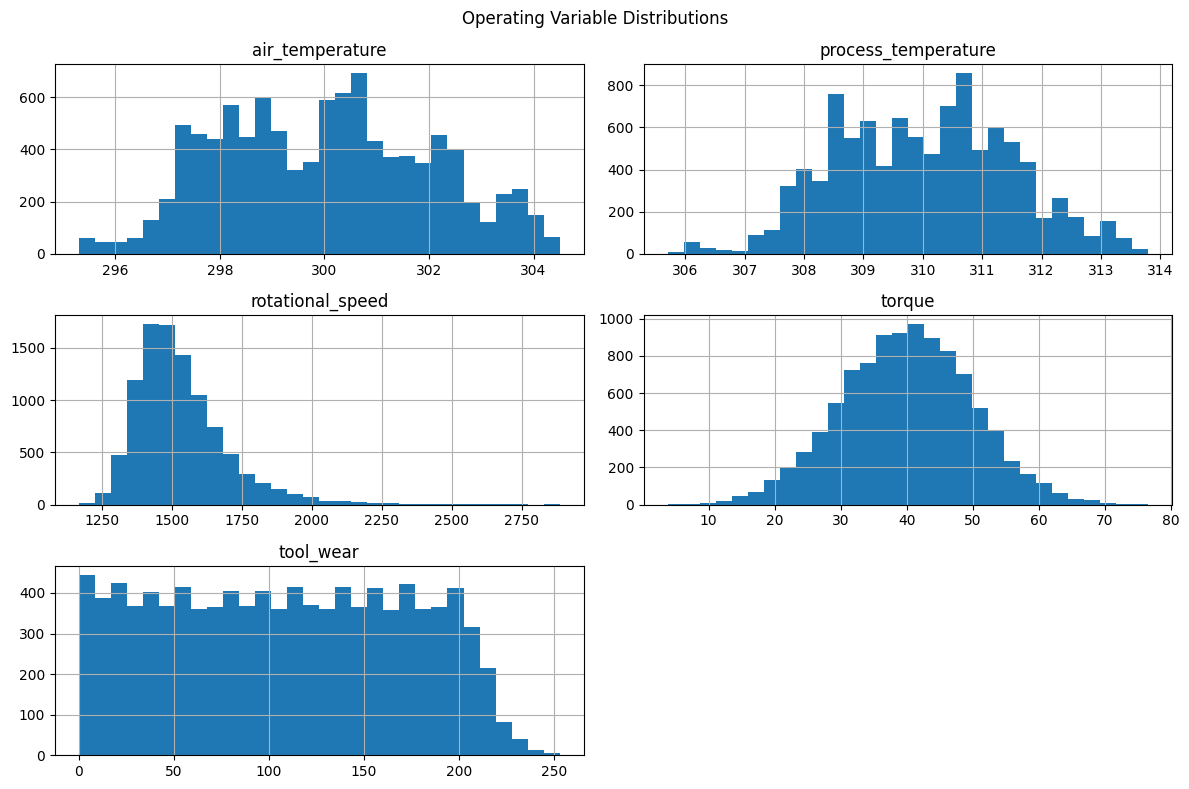

In [6]:
numeric_candidates = [
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear"
]
numeric_cols = [c for c in numeric_candidates if c in df.columns]

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.suptitle("Operating Variable Distributions")
plt.tight_layout()
plt.show()

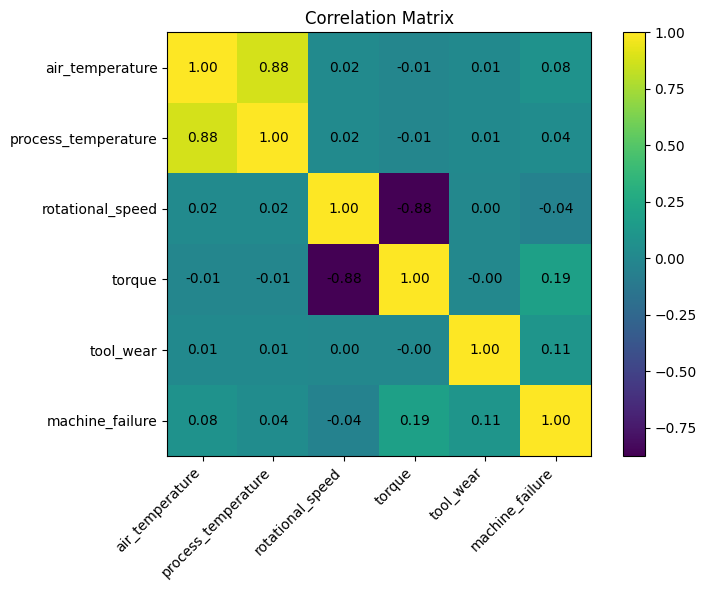

In [7]:
if numeric_cols:
    corr_cols = numeric_cols + [target]
    corr = df[corr_cols].corr(numeric_only=True)

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(corr.values)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.index)
    ax.set_title("Correlation Matrix")
    fig.colorbar(im, ax=ax)

    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

    plt.tight_layout()
    plt.show()

In [8]:
for col in numeric_cols:
    grouped = df.groupby(target)[col].agg(["mean", "median", "std"])
    print(f"\n{col}")
    display(grouped)


air_temperature


,mean,median,std
machine_failure,,,
0,299.973999,300.0,1.990748
1,300.886431,301.6,2.071473



process_temperature


,mean,median,std
machine_failure,,,
0,309.995570,310.0,1.486846
1,310.290265,310.4,1.363686



rotational_speed


,mean,median,std
machine_failure,,,
0,1540.260014,1507.0,167.394734
1,1496.486726,1365.0,384.943547



torque


,mean,median,std
machine_failure,,,
0,39.629655,39.9,9.472080
1,50.168142,53.7,16.374498



tool_wear


,mean,median,std
machine_failure,,,
0,106.693717,107.0,62.945790
1,143.781711,165.0,72.759876


## 4. Failure-mode analysis

**What we do**
- Examine the individual AI4I failure indicators: TWF, HDF, PWF, OSF, and RNF.
- Count how frequently each failure mechanism occurs.

**Why we do it**
- The target `machine_failure` indicates whether a failure occurred, while the mode labels provide diagnostic context about *how* failures occurred.
- In this dataset, HDF, OSF, and PWF are the most frequent recorded failure modes, which supports root-cause-oriented interpretation.
- These mode labels are later excluded from predictive inputs because using them would leak outcome information into the model.

Detected failure-mode columns: ['twf', 'hdf', 'pwf', 'osf', 'rnf']


,count
hdf,115
osf,98
pwf,95
twf,46
rnf,19


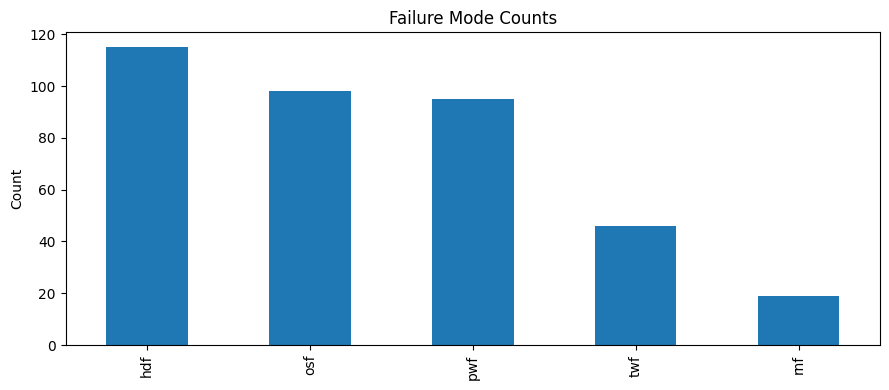

In [9]:
failure_mode_cols = [
    c for c in df.columns
    if c != target and (
        c.endswith("_failure")
        or c in {"twf", "hdf", "pwf", "osf", "rnf"}
    )
]

print("Detected failure-mode columns:", failure_mode_cols)

if failure_mode_cols:
    mode_counts = df[failure_mode_cols].sum().sort_values(ascending=False)
    display(mode_counts.to_frame("count"))

    mode_counts.plot(kind="bar", figsize=(9, 4), title="Failure Mode Counts")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 5. Feature engineering

**What we do**
- Create `temperature_difference`, `power_proxy`, and `wear_load` from the original operating variables.
- Retain the raw variables as well as the engineered relationships.

**Why we do it**
- Equipment failures often arise from interactions among operating conditions rather than from one sensor in isolation.
- `temperature_difference` represents thermal separation, `power_proxy` captures the torque-speed interaction, and `wear_load` combines accumulated wear with mechanical loading.
- These engineered variables improve engineering interpretability and give nonlinear models additional physically meaningful structure.

In [10]:
work = df.copy()

if {"process_temperature", "air_temperature"}.issubset(work.columns):
    work["temperature_difference"] = (
        work["process_temperature"] - work["air_temperature"]
    )

if {"torque", "rotational_speed"}.issubset(work.columns):
    # Proportional to mechanical power; constant conversion omitted for modeling.
    work["power_proxy"] = work["torque"] * work["rotational_speed"]

if {"tool_wear", "torque"}.issubset(work.columns):
    work["wear_load"] = work["tool_wear"] * work["torque"]

display(work.head())

,uid,product_id,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,machine_failure,twf,hdf,pwf,osf,rnf,temperature_difference,power_proxy,wear_load
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,66382.8,0.0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,65190.4,138.9
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,74001.2,247.0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,56603.5,276.5
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,56320.0,360.0


## 6. Prepare leakage-safe train / validation / test data

**What we do**
- Remove identifiers and failure-mode outcome labels from the predictor matrix.
- Split the data into **70% training, 15% validation, and 15% test** partitions using stratification.

**Why we do it**
- Removing TWF/HDF/PWF/OSF/RNF prevents target leakage: those variables describe failure outcomes and would make the prediction task unrealistically easy.
- The training set fits models, the validation set supports model/threshold decisions, and the untouched test set estimates final generalization.
- Stratification preserves the rare 3.4% failure rate in every partition.

In [11]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Exclude target, failure-mode labels (leakage), and identifiers.
drop_cols = [target] + failure_mode_cols
for c in ["uid", "udi", "product_id"]:
    if c in work.columns:
        drop_cols.append(c)

X = work.drop(columns=drop_cols, errors="ignore")
y = work[target].astype(int)

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# 70% train, 15% validation, 15% test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "failure rate:", f"{y_train.mean():.2%}")
print("Validation:", X_val.shape, "failure rate:", f"{y_val.mean():.2%}")
print("Test:", X_test.shape, "failure rate:", f"{y_test.mean():.2%}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train: (7000, 9) failure rate: 3.39%
Validation: (1500, 9) failure rate: 3.40%
Test: (1500, 9) failure rate: 3.40%
Numeric features: ['air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'temperature_difference', 'power_proxy', 'wear_load']
Categorical features: ['type']


## 7. Preprocessing

**What we do**
- Median-impute and standardize numerical variables.
- Impute and one-hot encode the machine-type categorical variable.

**Why we do it**
- A pipeline applies exactly the same transformations during training and inference, reducing preprocessing inconsistencies.
- Scaling is particularly important for Logistic Regression, while one-hot encoding allows all models to use machine type without imposing an artificial numeric ordering.

In [12]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## 8. Evaluation strategy

**What we do**
- Evaluate models using precision, recall, F1, ROC-AUC, PR-AUC, confusion matrices, and an adjustable classification threshold.
- Report failure-class performance explicitly.

**Why we do it**
- With only about **3.4% failures**, a model could exceed 96% accuracy by predicting almost everything as healthy.
- **PR-AUC** is especially useful here because it focuses on performance for the rare positive/failure class.
- Recall quantifies missed failures; precision quantifies how many maintenance alerts correspond to actual failures.

In [13]:
def evaluate_model(name, y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)

    metrics = {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities)
    }

    print(name)
    print("-" * len(name))
    print(classification_report(y_true, predictions, digits=4, zero_division=0))
    print(f"ROC-AUC: {metrics['ROC_AUC']:.4f}")
    print(f"PR-AUC : {metrics['PR_AUC']:.4f}")
    print(f"Threshold: {threshold:.3f}")

    ConfusionMatrixDisplay.from_predictions(y_true, predictions)
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

    return metrics

## 9. Logistic Regression baseline

**What we do**
- Train a class-balanced Logistic Regression model as an interpretable linear baseline.
- Evaluate it first on the validation set.

**Why we do it**
- A simple baseline establishes how much predictive signal exists before introducing nonlinear ensemble models.
- Logistic Regression also provides a useful interpretability benchmark for the accuracy-versus-complexity trade-off.
- Validation PR-AUC is **0.3561**, indicating that linear decision boundaries capture some signal but leave substantial nonlinear structure unexplained.

Logistic Regression (validation)
--------------------------------
              precision    recall  f1-score   support

           0     0.9913    0.8647    0.9237      1449
           1     0.1695    0.7843    0.2787        51

    accuracy                         0.8620      1500
   macro avg     0.5804    0.8245    0.6012      1500
weighted avg     0.9634    0.8620    0.9018      1500

ROC-AUC: 0.9048
PR-AUC : 0.3561
Threshold: 0.500


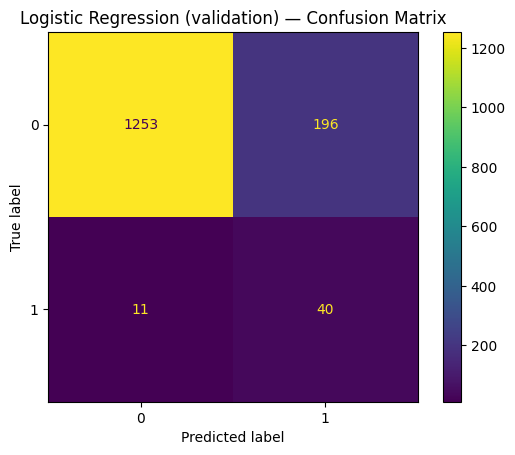

In [14]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
log_val_prob = logistic_model.predict_proba(X_val)[:, 1]
log_val_metrics = evaluate_model(
    "Logistic Regression (validation)", y_val, log_val_prob, threshold=0.50
)

## 10. Random Forest baseline

**What we do**
- Train a class-balanced Random Forest to model nonlinear interactions among operating variables.
- Compare its validation performance with the Logistic Regression baseline.

**Why we do it**
- Tree ensembles can naturally capture threshold effects and interactions among torque, speed, temperature, and wear.
- The baseline Random Forest increases validation PR-AUC to **0.8806**, a large improvement over Logistic Regression, showing that failure behavior is strongly nonlinear.

Random Forest baseline (validation)
-----------------------------------
              precision    recall  f1-score   support

           0     0.9911    0.9979    0.9945      1449
           1     0.9268    0.7451    0.8261        51

    accuracy                         0.9893      1500
   macro avg     0.9590    0.8715    0.9103      1500
weighted avg     0.9889    0.9893    0.9888      1500

ROC-AUC: 0.9793
PR-AUC : 0.8806
Threshold: 0.500


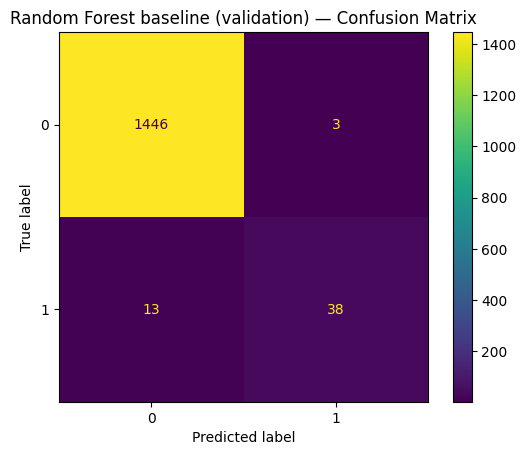

In [15]:
rf_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_baseline.fit(X_train, y_train)
rf_val_prob = rf_baseline.predict_proba(X_val)[:, 1]
rf_val_metrics = evaluate_model(
    "Random Forest baseline (validation)", y_val, rf_val_prob, threshold=0.50
)

## 11. Tune the Random Forest for rare-failure detection

**What we do**
- Use `RandomizedSearchCV` across tree count, depth, split rules, feature sampling, and class weighting.
- Optimize hyperparameters using **Average Precision (PR-AUC)** with four-fold cross-validation.

**Why we do it**
- Hyperparameter tuning improves the bias-variance trade-off and adapts the ensemble specifically to rare-failure detection.
- PR-AUC is used instead of accuracy so model selection rewards useful ranking of failure cases.
- The best cross-validation PR-AUC is **0.9007**; on validation, the tuned model reaches **0.9139 PR-AUC** with **0.8824 failure recall**.

Fitting 4 folds for each of 16 candidates, totalling 64 fits
Best CV PR-AUC: 0.9007
Best parameters:
  classifier__n_estimators: 500
  classifier__min_samples_split: 4
  classifier__min_samples_leaf: 2
  classifier__max_features: 0.7
  classifier__max_depth: 8
  classifier__criterion: entropy
  classifier__class_weight: balanced
Tuned Random Forest (validation)
--------------------------------
              precision    recall  f1-score   support

           0     0.9958    0.9910    0.9934      1449
           1     0.7759    0.8824    0.8257        51

    accuracy                         0.9873      1500
   macro avg     0.8859    0.9367    0.9096      1500
weighted avg     0.9884    0.9873    0.9877      1500

ROC-AUC: 0.9913
PR-AUC : 0.9139
Threshold: 0.500


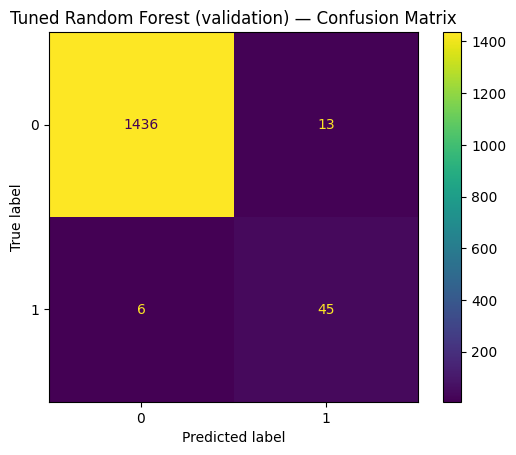

In [16]:
rf_search_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_distributions = {
    "classifier__n_estimators": [300, 500, 700, 900],
    "classifier__max_depth": [None, 8, 12, 16, 24],
    "classifier__min_samples_split": [2, 4, 8, 12],
    "classifier__min_samples_leaf": [1, 2, 3, 5],
    "classifier__max_features": ["sqrt", "log2", 0.7, 1.0],
    "classifier__class_weight": ["balanced", "balanced_subsample"],
    "classifier__criterion": ["gini", "entropy"]
}

search = RandomizedSearchCV(
    estimator=rf_search_pipeline,
    param_distributions=param_distributions,
    n_iter=16,
    scoring="average_precision",
    cv=4,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Best CV PR-AUC:", round(search.best_score_, 4))
print("Best parameters:")
for key, value in search.best_params_.items():
    print(f"  {key}: {value}")

best_val_prob = best_model.predict_proba(X_val)[:, 1]
best_val_metrics = evaluate_model(
    "Tuned Random Forest (validation)", y_val, best_val_prob, threshold=0.50
)

## 11A. HistGradientBoosting comparison model

**What we do**
- Train a histogram-based Gradient Boosting classifier with sample weights to account for class imbalance.
- Compare another nonlinear boosting strategy against the Logistic Regression and Random Forest approaches.

**Why we do it**
- Boosting builds trees sequentially to correct earlier errors, so it can capture a different form of nonlinear structure from bagged Random Forests.
- It provides a stronger model comparison and tests whether the AI4I failure boundary benefits from sequential boosting.
- In the recorded test results, HistGradientBoosting produces **ROC-AUC 0.9913** and **PR-AUC 0.9106**, the strongest ranking metrics among the three displayed models.

> **Methodology note:** this HistGradientBoosting result was evaluated directly on the test split in the current notebook. For a stricter experimental design, tune/compare all candidate models on the validation set first, choose one model, and evaluate that selected model only once on the test set.

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

# HistGradientBoosting does not support class_weight directly,
# so we create sample weights to handle class imbalance.

class_counts = y_train.value_counts()
weight_0 = len(y_train) / (2 * class_counts[0])
weight_1 = len(y_train) / (2 * class_counts[1])

sample_weights = y_train.map({
    0: weight_0,
    1: weight_1
})

hgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

hgb_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

hgb_pred = hgb_model.predict(X_test)
hgb_prob = hgb_model.predict_proba(X_test)[:, 1]

print("HistGradientBoosting Results")
print(classification_report(y_test, hgb_pred, digits=4))

print("ROC-AUC:", round(roc_auc_score(y_test, hgb_prob), 4))
print("PR-AUC :", round(average_precision_score(y_test, hgb_prob), 4))

HistGradientBoosting Results
              precision    recall  f1-score   support

           0     0.9952    0.9931    0.9941      1449
           1     0.8148    0.8627    0.8381        51

    accuracy                         0.9887      1500
   macro avg     0.9050    0.9279    0.9161      1500
weighted avg     0.9890    0.9887    0.9888      1500

ROC-AUC: 0.9913
PR-AUC : 0.9106


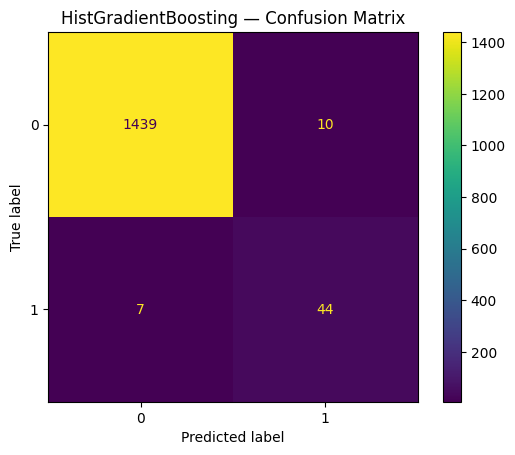

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, hgb_pred)
plt.title("HistGradientBoosting — Confusion Matrix")
plt.show()

## 11B. Cross-model comparison

**What we do**
- Generate failure probabilities for Logistic Regression, the tuned Random Forest, and HistGradientBoosting.
- Compare ROC-AUC and PR-AUC to measure each model's ability to rank failure risk.

**Why we do it**
- Comparing a linear model, a bagged tree ensemble, and a boosting model shows whether additional nonlinear complexity produces meaningful gains.
- Recorded test-set PR-AUC values are **0.4432 (Logistic Regression)**, **0.9029 (Random Forest)**, and **0.9106 (HistGradientBoosting)**.
- The two ensemble methods substantially outperform the linear baseline, while HistGradientBoosting gives the strongest overall probability ranking in this recorded comparison.

> Because these values include test-set comparisons, treat this table primarily as a descriptive model comparison. A publication-grade workflow would make the final model choice using validation results and reserve the test set for one final evaluation.

In [19]:
# Logistic Regression
log_pred = logistic_model.predict(X_test)
log_prob = logistic_model.predict_proba(X_test)[:, 1]

# Tuned Random Forest
rf_pred = best_model.predict(X_test)
rf_prob = best_model.predict_proba(X_test)[:, 1]

# HistGradientBoosting
hgb_pred = hgb_model.predict(X_test)
hgb_prob = hgb_model.predict_proba(X_test)[:, 1]

print("All model predictions ready")

All model predictions ready


In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, hgb_prob)
    ],
    "PR_AUC": [
        average_precision_score(y_test, log_prob),
        average_precision_score(y_test, rf_prob),
        average_precision_score(y_test, hgb_prob)
    ]
}).sort_values("PR_AUC", ascending=False)

display(comparison)

,Model,ROC_AUC,PR_AUC
2,HistGradientBoosting,0.991340,0.910627
1,Random Forest,0.980189,0.902933
0,Logistic Regression,0.937198,0.443191


## 12. Maintenance-oriented threshold tuning

**What we do**
- Tune the Random Forest decision threshold on the validation set rather than automatically using 0.50.
- Search for a threshold that targets high failure recall while maximizing precision among eligible thresholds.

**Why we do it**
- Predictive-maintenance decisions depend on operational costs: missed failures and unnecessary inspections have different consequences.
- The selected validation threshold is **0.557**, with validation precision **0.9184** and recall **0.8824**.
- Threshold tuning changes the maintenance policy without retraining the underlying model.

Chosen threshold: 0.5570
Validation precision: 0.9184
Validation recall:    0.8824
Tuned Random Forest + maintenance threshold (validation)
--------------------------------------------------------
              precision    recall  f1-score   support

           0     0.9959    0.9972    0.9966      1449
           1     0.9184    0.8824    0.9000        51

    accuracy                         0.9933      1500
   macro avg     0.9571    0.9398    0.9483      1500
weighted avg     0.9932    0.9933    0.9933      1500

ROC-AUC: 0.9913
PR-AUC : 0.9139
Threshold: 0.557


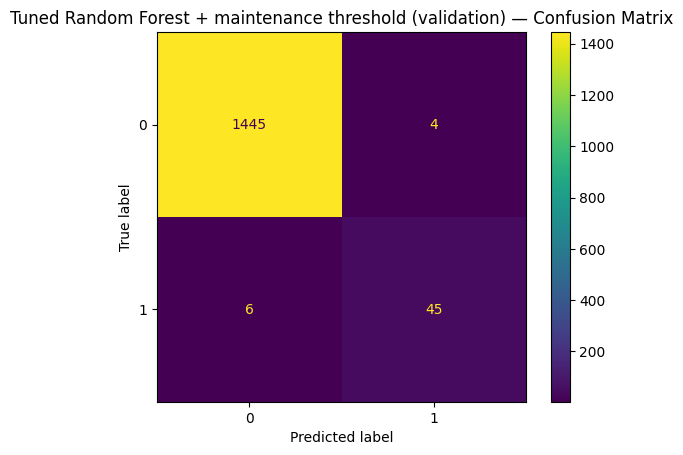

In [21]:
TARGET_RECALL = 0.85

precision, recall, thresholds = precision_recall_curve(y_val, best_val_prob)

# precision/recall contain one extra endpoint compared with thresholds.
precision_t = precision[:-1]
recall_t = recall[:-1]

eligible = np.where(recall_t >= TARGET_RECALL)[0]

if len(eligible) > 0:
    # Among thresholds meeting the recall target, maximize precision.
    best_idx = eligible[np.argmax(precision_t[eligible])]
else:
    # Fallback: maximize F1 if target recall cannot be reached.
    f1_values = 2 * precision_t * recall_t / (precision_t + recall_t + 1e-12)
    best_idx = int(np.nanargmax(f1_values))

optimal_threshold = float(thresholds[best_idx])

print(f"Chosen threshold: {optimal_threshold:.4f}")
print(f"Validation precision: {precision_t[best_idx]:.4f}")
print(f"Validation recall:    {recall_t[best_idx]:.4f}")

threshold_metrics_val = evaluate_model(
    "Tuned Random Forest + maintenance threshold (validation)",
    y_val,
    best_val_prob,
    threshold=optimal_threshold
)

## 13. Final evaluation on the untouched test set

**What we do**
- Evaluate the tuned Random Forest on the held-out test data at both the standard 0.50 threshold and the validation-selected 0.557 threshold.
- Compare discrimination metrics and maintenance-alert classification metrics.

**Why we do it**
- The test set estimates how the selected Random Forest workflow generalizes beyond the data used for fitting and threshold selection.
- Raising the threshold improves test precision from **0.7458 to 0.8776** and F1 from **0.8000 to 0.8600**, while recall decreases slightly from **0.8627 to 0.8431**.
- ROC-AUC (**0.9802**) and PR-AUC (**0.9029**) remain unchanged because threshold adjustment changes the operating decision, not the underlying probability ranking.

Tuned RF — default threshold (TEST)
-----------------------------------
              precision    recall  f1-score   support

           0     0.9951    0.9896    0.9924      1449
           1     0.7458    0.8627    0.8000        51

    accuracy                         0.9853      1500
   macro avg     0.8705    0.9262    0.8962      1500
weighted avg     0.9867    0.9853    0.9858      1500

ROC-AUC: 0.9802
PR-AUC : 0.9029
Threshold: 0.500


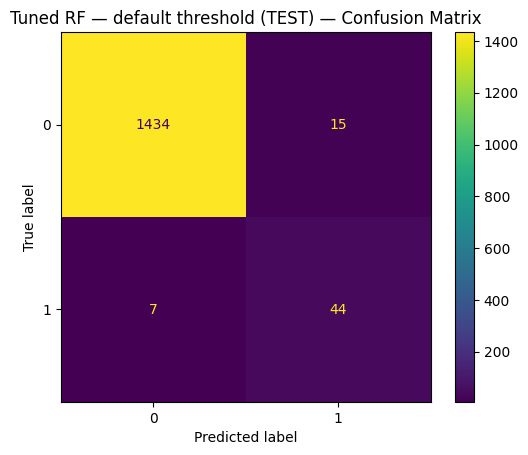

Tuned RF — maintenance threshold (TEST)
---------------------------------------
              precision    recall  f1-score   support

           0     0.9945    0.9959    0.9952      1449
           1     0.8776    0.8431    0.8600        51

    accuracy                         0.9907      1500
   macro avg     0.9360    0.9195    0.9276      1500
weighted avg     0.9905    0.9907    0.9906      1500

ROC-AUC: 0.9802
PR-AUC : 0.9029
Threshold: 0.557


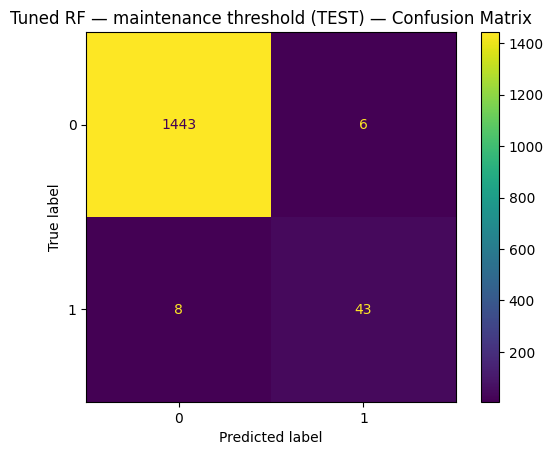

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,,
Tuned RF — default threshold (TEST),0.500,0.9853,0.7458,0.8627,0.80,0.9802,0.9029
Tuned RF — maintenance threshold (TEST),0.557,0.9907,0.8776,0.8431,0.86,0.9802,0.9029


In [22]:
test_prob = best_model.predict_proba(X_test)[:, 1]

metrics_default = evaluate_model(
    "Tuned RF — default threshold (TEST)",
    y_test,
    test_prob,
    threshold=0.50
)

metrics_tuned = evaluate_model(
    "Tuned RF — maintenance threshold (TEST)",
    y_test,
    test_prob,
    threshold=optimal_threshold
)

comparison = pd.DataFrame([
    metrics_default,
    metrics_tuned
]).set_index("Model")

display(comparison.round(4))

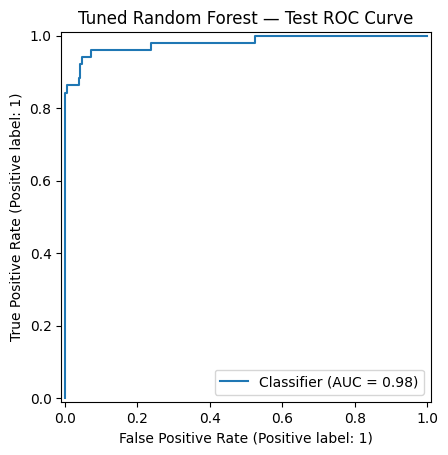

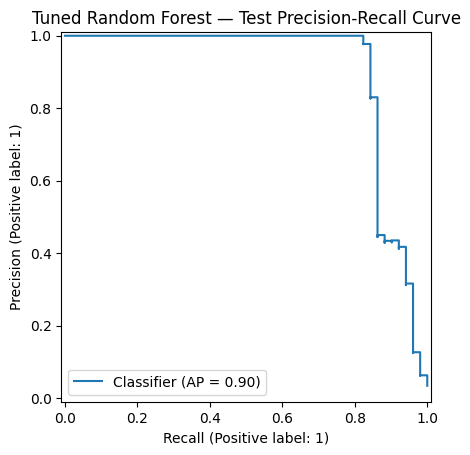

In [23]:
RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("Tuned Random Forest — Test ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob)
plt.title("Tuned Random Forest — Test Precision-Recall Curve")
plt.show()

## 14. Feature importance

**What we do**
- Extract global feature importance from the tuned Random Forest.
- Rank raw and engineered operating variables by their contribution to the ensemble.

**Why we do it**
- Predictive-maintenance models should provide engineering evidence, not only a failure flag.
- The strongest features are **rotational speed (0.212)**, **power proxy (0.203)**, **torque (0.171)**, and **tool wear (0.150)**.
- The engineered `wear_load` and `temperature_difference` also contribute meaningfully, supporting the value of interaction-based features.

,feature,importance
2,num__rotational_speed,0.212305
6,num__power_proxy,0.202843
3,num__torque,0.171239
4,num__tool_wear,0.149891
7,num__wear_load,0.109762
5,num__temperature_difference,0.099183
0,num__air_temperature,0.028394
1,num__process_temperature,0.016604
9,cat__type_L,0.004685
10,cat__type_M,0.003837


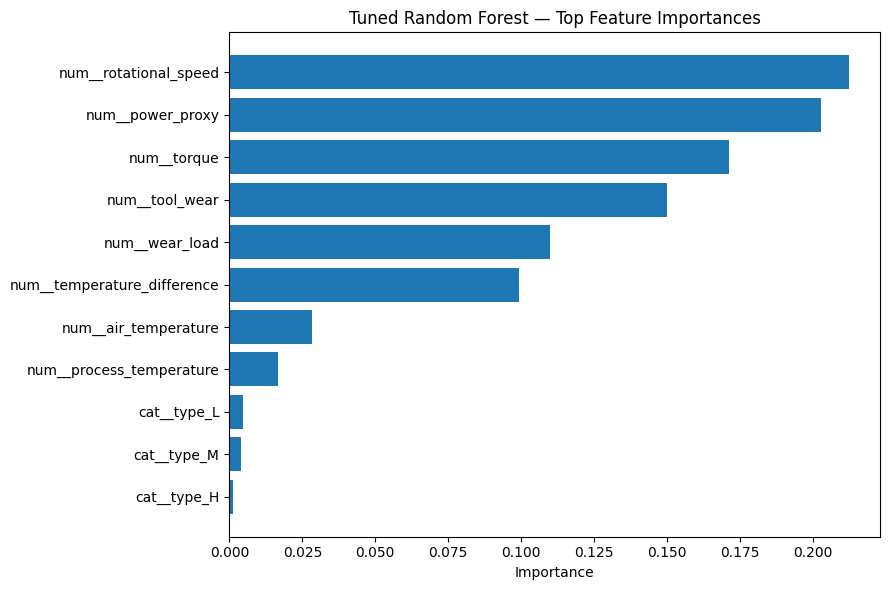

In [24]:
best_preprocessor = best_model.named_steps["preprocessor"]
best_classifier = best_model.named_steps["classifier"]

feature_names = best_preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": best_classifier.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(15))

top = importance_df.head(15).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance"])
plt.title("Tuned Random Forest — Top Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 15. Machine-level risk scoring

**What we do**
- Convert continuous failure scores into LOW, MODERATE, HIGH, and CRITICAL risk bands.
- Add a binary maintenance flag based on the tuned operational threshold.

**Why we do it**
- Maintenance teams need an actionable risk signal rather than only a raw probability.
- Separating descriptive risk bands from the actual inspection threshold makes the model output easier to interpret and deploy in decision-support workflows.

In [25]:
def risk_level(score):
    if score < 0.20:
        return "LOW"
    elif score < 0.50:
        return "MODERATE"
    elif score < 0.80:
        return "HIGH"
    return "CRITICAL"

results = X_test.copy()
results["actual_failure"] = y_test.to_numpy()
results["failure_score"] = test_prob
results["maintenance_flag"] = (test_prob >= optimal_threshold).astype(int)
results["risk_level"] = results["failure_score"].apply(risk_level)

display(
    results.sort_values("failure_score", ascending=False).head(20)
)

,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,temperature_difference,power_proxy,wear_load,actual_failure,failure_score,maintenance_flag,risk_level
8245,M,299.0,310.3,1303,68.6,111,11.3,89385.8,7614.6,1,1.000000,1,CRITICAL
6799,M,301.1,310.7,2636,12.2,100,9.6,32159.2,1220.0,1,0.999966,1,CRITICAL
4570,L,302.8,310.9,1312,52.2,40,8.1,68486.4,2088.0,1,0.999596,1,CRITICAL
4270,L,302.6,310.9,1331,52.0,154,8.3,69212.0,8008.0,1,0.999504,1,CRITICAL
7997,M,301.0,312.2,2710,9.7,143,11.2,26287.0,1387.1,1,0.997865,1,CRITICAL
1391,L,298.9,310.2,2737,8.8,142,11.3,24085.6,1249.6,1,0.997865,1,CRITICAL
8398,L,298.5,309.7,2617,12.1,102,11.2,31665.7,1234.2,1,0.997640,1,CRITICAL
4729,L,303.4,311.8,1306,61.0,215,8.4,79666.0,13115.0,1,0.994643,1,CRITICAL
4565,H,302.7,310.8,1275,55.0,25,8.1,70125.0,1375.0,1,0.993516,1,CRITICAL
6078,L,300.8,310.7,1339,59.1,203,9.9,79134.9,11997.3,1,0.991782,1,CRITICAL


## 16. Predict one machine

**What we do**
- Pass one held-out machine condition through the complete preprocessing and tuned Random Forest pipeline.
- Return the failure score, risk category, maintenance threshold, and recommended flag.

**Why we do it**
- This demonstrates how the trained model would be used for a new machine observation in practice.
- The recorded example receives a **0.01% failure score**, is classified as **LOW risk**, and receives a **CONTINUE / MONITOR** recommendation.

In [26]:
sample_machine = X_test.iloc[[0]].copy()
score = best_model.predict_proba(sample_machine)[0, 1]
maintenance_flag = int(score >= optimal_threshold)

print("Machine inputs:")
display(sample_machine)
print(f"Failure score: {score:.2%}")
print(f"Risk level: {risk_level(score)}")
print(f"Maintenance threshold: {optimal_threshold:.3f}")
print("Maintenance flag:", "INSPECT" if maintenance_flag else "CONTINUE / MONITOR")

Machine inputs:


,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,temperature_difference,power_proxy,wear_load
1529,L,298.1,309.0,1557,36.0,56,10.9,56052.0,2016.0


Failure score: 0.01%
Risk level: LOW
Maintenance threshold: 0.557
Maintenance flag: CONTINUE / MONITOR


## 17. Optional SHAP explainability

**What we do**
- Use SHAP values to explain how transformed features push model predictions toward or away from failure.
- Produce a summary view over a subset of test observations.

**Why we do it**
- Feature importance explains the model globally, whereas SHAP helps explain individual prediction behavior and direction of influence.
- This supports transparent maintenance reasoning by connecting predicted risk to specific operating conditions.

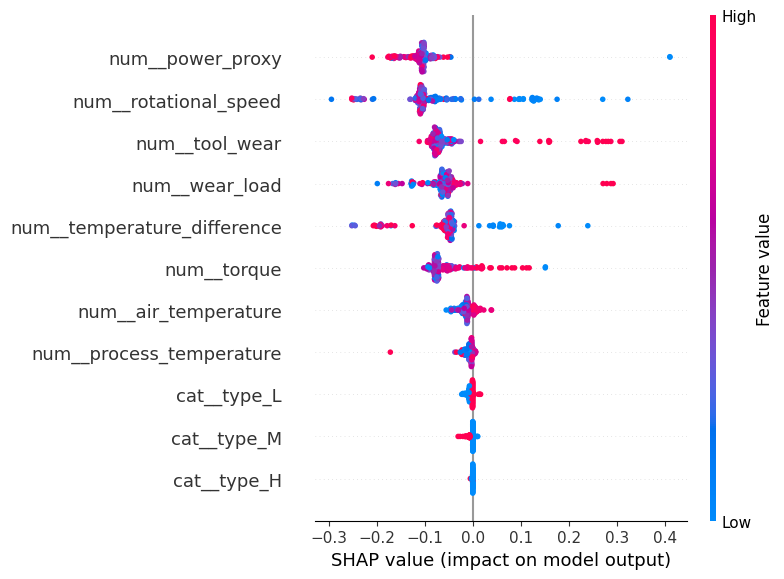

In [27]:
try:
    import shap

    transformed_test = best_preprocessor.transform(X_test)
    sample = transformed_test[:200]

    explainer = shap.TreeExplainer(best_classifier)
    shap_values = explainer.shap_values(sample)

    if isinstance(shap_values, list):
        values_to_plot = shap_values[1]
    else:
        values_to_plot = shap_values
        if getattr(values_to_plot, "ndim", 0) == 3:
            values_to_plot = values_to_plot[:, :, 1]

    shap.summary_plot(
        values_to_plot,
        sample,
        feature_names=feature_names,
        show=True
    )

except Exception as e:
    print("SHAP section skipped:", e)

## 18. Results, interpretation, and project findings

### Model comparison

| Model | ROC-AUC | PR-AUC | Interpretation |
|---|---:|---:|---|
| Logistic Regression | 0.9372 | 0.4432 | Useful interpretable baseline, but limited on the rare failure class |
| Tuned Random Forest | 0.9802 | 0.9029 | Strong nonlinear failure ranking and a good precision/recall balance |
| HistGradientBoosting | **0.9913** | **0.9106** | Best recorded ranking performance among the three models |

**Main comparison**
- Both tree-based ensemble models dramatically outperform Logistic Regression on PR-AUC, confirming that equipment-failure behavior depends on nonlinear operating interactions.
- HistGradientBoosting gives the highest recorded ROC-AUC and PR-AUC.
- The tuned Random Forest remains especially useful for this notebook because it has a complete validation-based threshold-selection workflow, feature-importance analysis, risk scoring, and SHAP interpretation.

> **Experimental-design caveat:** HistGradientBoosting was evaluated directly on the test split in the current run. Therefore, it should be described as the best *recorded test ranking model*, not as a formally selected final model. A stricter follow-up experiment should tune all three models using only training/validation data and then evaluate the chosen winner once on the test set.

### Effect of maintenance threshold tuning

For the tuned Random Forest on the test set:

| Decision rule | Precision | Recall | F1 | Accuracy |
|---|---:|---:|---:|---:|
| Default threshold = 0.50 | 0.7458 | **0.8627** | 0.8000 | 0.9853 |
| Tuned threshold = 0.557 | **0.8776** | 0.8431 | **0.8600** | **0.9907** |

- Increasing the threshold from 0.50 to 0.557 makes the maintenance policy more selective.
- Failure precision rises substantially, meaning a larger fraction of generated maintenance alerts correspond to actual failures.
- Recall falls slightly on the test set, so the tuned threshold trades a small number of additional missed failures for considerably fewer false alarms.
- The higher F1 score indicates a better overall precision/recall balance for this test set.
- ROC-AUC and PR-AUC do not change with the threshold because they evaluate the ranking produced by the model across many possible thresholds.

### Failure-associated operating patterns

The exploratory analysis shows meaningful differences between healthy and failed observations:

- Mean **torque** increases from about **39.6 Nm** for healthy observations to **50.2 Nm** for failures.
- Mean **tool wear** increases from about **106.7 min** to **143.8 min**.
- Failed observations have lower mean rotational speed (**~1496 rpm**) than healthy observations (**~1540 rpm**) and much greater speed variability.
- Air temperature is also somewhat higher for failure observations.

These patterns indicate that failure is associated with combinations of mechanical loading, speed behavior, wear accumulation, and thermal conditions rather than one variable alone.

### Failure modes

Recorded failure-mode counts are:

- HDF: **115**
- OSF: **98**
- PWF: **95**
- TWF: **46**
- RNF: **19**

HDF, OSF, and PWF therefore account for the largest individual mode counts in this dataset. These labels were used for diagnostic analysis only and excluded from model inputs to prevent target leakage.

### Most influential predictors

The tuned Random Forest ranks the following variables highest:

1. **Rotational speed** — 0.212
2. **Power proxy** — 0.203
3. **Torque** — 0.171
4. **Tool wear** — 0.150
5. **Wear load** — 0.110
6. **Temperature difference** — 0.099

This is an important engineering result: three of the top six predictors are either interaction-oriented or directly connected to mechanical loading. The engineered `power_proxy` and `wear_load` features therefore add useful structure beyond the original raw measurements.

### Practical maintenance interpretation

The workflow does more than classify failure:

- The model produces a continuous failure-risk score.
- The validation-selected threshold converts that score into an inspection/monitoring decision.
- Risk bands provide an easily communicated operational status.
- Feature importance and SHAP provide evidence about *why* risk is elevated.

This makes the project a small end-to-end **predictive-maintenance decision-support system**, rather than only a classification exercise.

### Overall conclusion

The AI4I 2020 data contains strong nonlinear signals for machine-failure classification. Ensemble tree models are substantially more effective than the linear baseline, with recorded PR-AUC values above **0.90** for both tuned Random Forest and HistGradientBoosting. Mechanical operating relationships—particularly rotational speed, torque, power-related interactions, and tool wear—dominate the predictive signal.

The tuned Random Forest provides a strong balance of predictive performance and interpretability, while HistGradientBoosting demonstrates that boosting can slightly improve probability ranking. Threshold tuning further shows that maintenance policy can be adjusted independently of model training to control the trade-off between missed failures and unnecessary inspections.

### Limitations and next steps

- AI4I is a synthetic/static classification dataset, so this analysis predicts **failure risk at an observation**, not true Remaining Useful Life (RUL).
- Risk bands are heuristic and should be calibrated against real maintenance costs before operational use.
- A stricter model-selection experiment should compare/tune all candidate models on validation data before a single final test evaluation.
- Future work can extend this workflow to temporal degradation datasets such as NASA C-MAPSS for **RUL estimation, uncertainty quantification, and risk-aware maintenance scheduling**.

## 19. Lightweight extension: diagnostic and decision-support analysis

The main AI4I workflow already covers failure classification, model comparison, threshold tuning, and explainability.  
To keep this project distinct from the NASA C-MAPSS RUL project, the remaining extensions focus on **diagnosis, robustness, and maintenance decisions** rather than temporal degradation or RUL estimation.

This extension adds:

- Failure-mode operating profiles for root-cause-oriented interpretation
- Performance checks across machine types and operating regimes
- Cost-aware threshold selection for maintenance decisions
- A small reusable inference function for deployment-style use

These cells are intentionally lightweight and should run quickly once the main notebook has been executed.

## 20. Failure-mode operating profiles

**What we do**
- Compare the median operating conditions associated with TWF, HDF, PWF, OSF, and RNF.
- Standardize these profiles so the dominant operating signatures of each failure mode are easier to compare.

**Why**
- The binary classifier answers *whether failure risk is high*.
- This diagnostic analysis adds evidence about *which operating conditions are associated with different failure mechanisms* without using failure-mode labels as predictive inputs.
- This strengthens the root-cause-analysis component of the project without introducing another expensive model.

In [28]:
# Diagnostic-only analysis: failure mode labels are NOT used as predictors.
mode_cols = [c for c in ["twf", "hdf", "pwf", "osf", "rnf"] if c in work.columns]
profile_features = [
    c for c in [
        "air_temperature",
        "process_temperature",
        "rotational_speed",
        "torque",
        "tool_wear",
        "temperature_difference",
        "power_proxy",
        "wear_load"
    ]
    if c in work.columns
]

mode_profiles = {}

for mode in mode_cols:
    subset = work.loc[work[mode] == 1, profile_features]
    if len(subset) > 0:
        mode_profiles[mode.upper()] = subset.median()

mode_profile_df = pd.DataFrame(mode_profiles).T

print("Failure-mode median operating profiles")
display(mode_profile_df.round(2))

Failure-mode median operating profiles


,air_temperature,process_temperature,rotational_speed,torque,tool_wear,temperature_difference,power_proxy,wear_load
TWF,300.45,310.25,1516.0,37.75,214.5,9.6,57498.0,7982.85
HDF,302.50,310.70,1346.0,52.60,106.0,8.3,70125.0,5580.00
PWF,300.40,310.20,1386.0,63.60,100.0,9.7,86902.2,3608.80
OSF,300.05,310.10,1360.5,57.70,207.0,10.0,78068.2,11689.40
RNF,300.80,311.00,1481.0,45.70,144.0,9.6,65192.0,6124.80


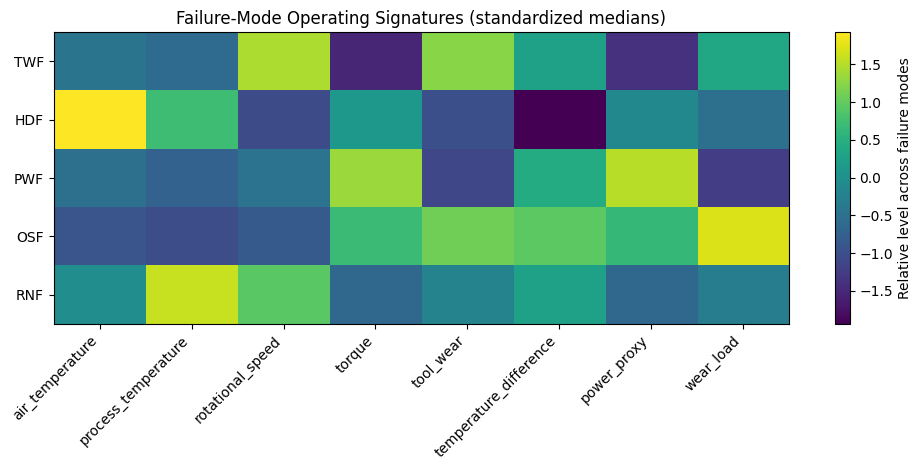

In [29]:
# Standardize each feature across failure modes for an easier visual comparison.
if len(mode_profile_df) > 1:
    z = (mode_profile_df - mode_profile_df.mean()) / mode_profile_df.std(ddof=0).replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(10, 4.8))
    im = ax.imshow(z.fillna(0).values, aspect="auto")

    ax.set_xticks(range(len(z.columns)))
    ax.set_xticklabels(z.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(z.index)))
    ax.set_yticklabels(z.index)
    ax.set_title("Failure-Mode Operating Signatures (standardized medians)")

    fig.colorbar(im, ax=ax, label="Relative level across failure modes")
    plt.tight_layout()
    plt.show()

### Interpretation guide

- Positive values in the heatmap indicate that a failure mode tends to occur at relatively higher values of that operating variable compared with other modes.
- Negative values indicate relatively lower values.
- Treat these as **associations**, not causal proof. The AI4I data is useful for controlled predictive-maintenance experimentation, but it does not establish physical causality by itself.

## 21. Robustness across machine types

**What we do**
- Evaluate the tuned Random Forest separately for machine types L, M, and H.
- Report the number of observations, failure prevalence, ROC-AUC, PR-AUC, precision, recall, and F1 at the selected maintenance threshold.

**Why**
- A model can look strong overall while performing unevenly across subgroups.
- This quick check provides evidence about whether the maintenance model behaves consistently across product-quality categories.

In [30]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

robustness_rows = []

test_prob_rf = best_model.predict_proba(X_test)[:, 1]
test_pred_rf = (test_prob_rf >= optimal_threshold).astype(int)

if "type" in X_test.columns:
    for machine_type in sorted(X_test["type"].dropna().unique()):
        mask = (X_test["type"] == machine_type).to_numpy()
        y_group = y_test.iloc[np.where(mask)[0]]
        prob_group = test_prob_rf[mask]
        pred_group = test_pred_rf[mask]

        row = {
            "Machine Type": machine_type,
            "N": int(mask.sum()),
            "Failure Rate": float(y_group.mean()),
            "Precision": precision_score(y_group, pred_group, zero_division=0),
            "Recall": recall_score(y_group, pred_group, zero_division=0),
            "F1": f1_score(y_group, pred_group, zero_division=0),
        }

        # AUC metrics require both classes to be present.
        if y_group.nunique() == 2:
            row["ROC_AUC"] = roc_auc_score(y_group, prob_group)
            row["PR_AUC"] = average_precision_score(y_group, prob_group)
        else:
            row["ROC_AUC"] = np.nan
            row["PR_AUC"] = np.nan

        robustness_rows.append(row)

    robustness_df = pd.DataFrame(robustness_rows)
    display(
        robustness_df.style.format({
            "Failure Rate": "{:.2%}",
            "Precision": "{:.3f}",
            "Recall": "{:.3f}",
            "F1": "{:.3f}",
            "ROC_AUC": "{:.3f}",
            "PR_AUC": "{:.3f}"
        })
    )
else:
    print("Machine type is not available in X_test.")

,Machine Type,N,Failure Rate,Precision,Recall,F1,ROC_AUC,PR_AUC
0,H,143,3.50%,1.000,0.600,0.750,0.984,0.863
1,L,885,2.94%,0.793,0.885,0.836,0.988,0.917
2,M,472,4.24%,1.000,0.850,0.919,0.966,0.909


### Interpretation guide

- Similar scores across L/M/H indicate better subgroup robustness.
- Large differences suggest that operating category should be monitored explicitly during deployment.
- Because failures are rare, subgroup metrics can be noisy; the goal here is a practical diagnostic check rather than a definitive fairness or reliability study.

## 22. Cost-aware maintenance threshold

**What we do**
- Convert false negatives and false positives into simple maintenance costs.
- Search for the threshold that minimizes total decision cost on the **validation set**.
- Evaluate that cost-selected policy on the test set.

**Why**
- Precision/recall tuning is useful, but maintenance decisions ultimately depend on operational consequences.
- Missing a failure is usually more expensive than an unnecessary inspection.
- A cost-based threshold makes the decision logic more directly interpretable to engineering and maintenance teams.

The default example below assumes:

- Missed failure (false negative): cost = 10
- Unnecessary inspection (false positive): cost = 1

These are illustrative relative costs, not real monetary values.

In [31]:
from sklearn.metrics import confusion_matrix

COST_FN = 10.0
COST_FP = 1.0

val_prob_rf = best_model.predict_proba(X_val)[:, 1]

threshold_grid = np.linspace(0.05, 0.95, 91)
cost_rows = []

for threshold in threshold_grid:
    pred = (val_prob_rf >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()

    total_cost = COST_FN * fn + COST_FP * fp

    cost_rows.append({
        "threshold": threshold,
        "false_positives": fp,
        "false_negatives": fn,
        "total_cost": total_cost
    })

cost_df = pd.DataFrame(cost_rows)
best_cost_row = cost_df.loc[cost_df["total_cost"].idxmin()]
cost_threshold = float(best_cost_row["threshold"])

print(f"Cost-optimal validation threshold: {cost_threshold:.2f}")
print(f"Validation cost at optimum: {best_cost_row['total_cost']:.1f}")
display(cost_df.sort_values("total_cost").head(10))

Cost-optimal validation threshold: 0.45
Validation cost at optimum: 63.0


,threshold,false_positives,false_negatives,total_cost
40,0.45,23,4,63.0
50,0.55,6,6,66.0
38,0.43,26,4,66.0
39,0.44,26,4,66.0
49,0.54,7,6,67.0
37,0.42,28,4,68.0
31,0.36,40,3,70.0
36,0.41,30,4,70.0
35,0.40,30,4,70.0
47,0.52,12,6,72.0


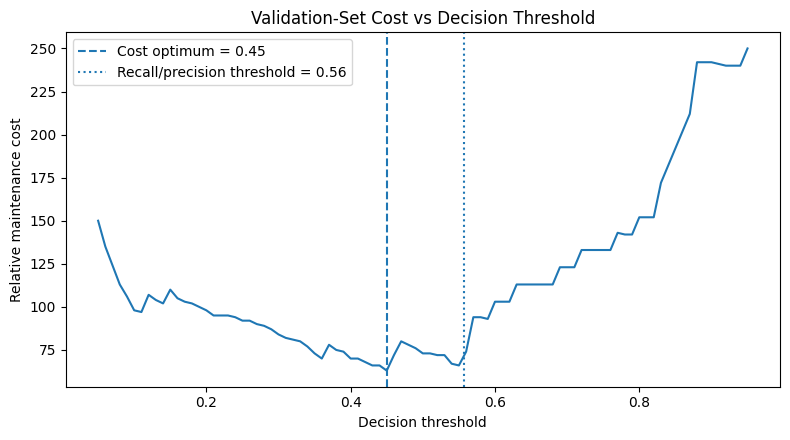

In [32]:
plt.figure(figsize=(8, 4.5))
plt.plot(cost_df["threshold"], cost_df["total_cost"])
plt.axvline(cost_threshold, linestyle="--", label=f"Cost optimum = {cost_threshold:.2f}")
plt.axvline(optimal_threshold, linestyle=":", label=f"Recall/precision threshold = {optimal_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Relative maintenance cost")
plt.title("Validation-Set Cost vs Decision Threshold")
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Evaluate the cost-selected threshold on the untouched test set.
cost_test_pred = (test_prob_rf >= cost_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, cost_test_pred, labels=[0, 1]).ravel()

cost_test_summary = pd.DataFrame([{
    "Threshold": cost_threshold,
    "Precision": precision_score(y_test, cost_test_pred, zero_division=0),
    "Recall": recall_score(y_test, cost_test_pred, zero_division=0),
    "F1": f1_score(y_test, cost_test_pred, zero_division=0),
    "False Positives": fp,
    "False Negatives": fn,
    "Relative Cost": COST_FP * fp + COST_FN * fn
}])

display(cost_test_summary.round(4))

,Threshold,Precision,Recall,F1,False Positives,False Negatives,Relative Cost
0,0.45,0.6377,0.8627,0.7333,25,7,95.0


### What this adds to the project

The original threshold was selected using a recall/precision target.  
This section demonstrates a second decision rule based on **expected operational cost**.

That distinction is useful in predictive maintenance:

- The ML model estimates failure risk.
- The threshold represents the maintenance policy.
- Different factories can use the same model but choose different thresholds according to downtime, inspection, safety, and replacement costs.

## 23. Lightweight deployment helper

**What we do**
- Wrap the tuned model and maintenance threshold in a reusable prediction function.
- Optionally save the fitted pipeline and threshold to disk.

**Why**
- This demonstrates how notebook results can be turned into a reusable maintenance inference component.
- It provides an easy bridge to a future Streamlit dashboard or REST API without building a full application here.

In [34]:
import joblib

def predict_maintenance_risk(machine_data, model=best_model, threshold=optimal_threshold):
    '''
    machine_data:
        pandas DataFrame with the same input columns used during training.
    '''
    probability = model.predict_proba(machine_data)[:, 1]

    result = machine_data.copy()
    result["failure_probability"] = probability
    result["maintenance_flag"] = (probability >= threshold).astype(int)

    def risk_band(p):
        if p < 0.30:
            return "LOW"
        elif p < 0.60:
            return "MODERATE"
        elif p < 0.80:
            return "HIGH"
        return "CRITICAL"

    result["risk_level"] = [risk_band(p) for p in probability]
    return result

# Example: score three test observations.
display(predict_maintenance_risk(X_test.iloc[:3]))

,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,temperature_difference,power_proxy,wear_load,failure_probability,maintenance_flag,risk_level
1529,L,298.1,309.0,1557,36.0,56,10.9,56052.0,2016.0,0.000065,0,LOW
8572,M,297.7,308.5,1559,35.2,127,10.8,54876.8,4470.4,0.001228,0,LOW
4330,L,301.5,309.8,1549,38.5,81,8.3,59636.5,3118.5,0.006844,0,LOW


In [35]:
# Optional export for a future dashboard/API.
joblib.dump(
    {
        "model": best_model,
        "maintenance_threshold": float(optimal_threshold),
        "cost_threshold": float(cost_threshold)
    },
    "ai4i_predictive_maintenance_model.joblib"
)

print("Saved: ai4i_predictive_maintenance_model.joblib")

Saved: ai4i_predictive_maintenance_model.joblib


In [41]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [43]:
joblib.dump(
    {
        "model": best_model,
        "maintenance_threshold": float(optimal_threshold),
        "cost_threshold": float(cost_threshold)
    },
    "/content/drive/MyDrive/ai4i_predictive_maintenance_model.joblib"
)

['/content/drive/MyDrive/ai4i_predictive_maintenance_model.joblib']

## 24. Extension summary

These additions deliberately keep the AI4I project focused on **failure-risk classification and maintenance decision support**:

1. **Failure-mode profiles** add diagnostic/root-cause context.
2. **Subgroup robustness** checks whether performance is consistent across machine types.
3. **Cost-aware thresholding** connects model output to operational maintenance consequences.
4. **Reusable inference** demonstrates a simple deployment pathway.

### Separation from the NASA C-MAPSS FD004 project

Keep the more advanced prognostics topics in the C-MAPSS project:

- temporal degradation modeling
- Remaining Useful Life estimation
- operating-condition heterogeneity
- calibrated uncertainty / prediction intervals
- probabilistic prognostics

This separation gives the two projects distinct stories:

**AI4I:** Explainable failure-risk classification and maintenance decision support.  
**C-MAPSS FD004:** Probabilistic RUL prognostics under heterogeneous operating conditions.